# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [5]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

(54990, 30)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Fatal.Serious.Fraction,Destroyed,Plane.Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,CESSNA 140


,Total.Passengers,Fatal.Serious.Fraction,Destroyed
count,54990.000000,54990.000000,54990.000000
mean,3.789162,0.275100,0.210602
std,18.947519,0.431199,0.407740
min,1.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000
75%,2.000000,0.750000,0.000000
max,699.000000,1.000000,1.000000


c:\Users\pc\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


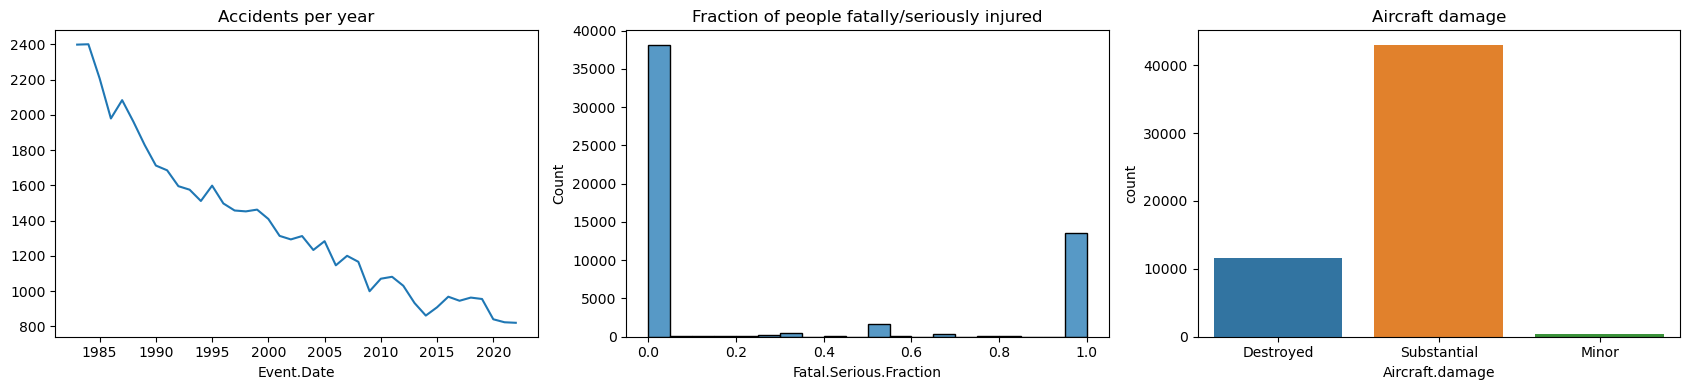

In [6]:
df = pd.read_csv('Aviation_Data_Cleaned.csv', parse_dates=['Event.Date'])
print(df.shape)
display(df.head())
display(df[['Total.Passengers', 'Fatal.Serious.Fraction', 'Destroyed']].describe())

# Overview: accidents per year, and the distribution of the two outcome measures
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df['Event.Date'].dt.year.value_counts().sort_index().plot(ax=axes[0], title='Accidents per year')
sns.histplot(df['Fatal.Serious.Fraction'], bins=20, ax=axes[1])
axes[1].set_title('Fraction of people fatally/seriously injured')
sns.countplot(data=df, x='Aircraft.damage', order=['Destroyed', 'Substantial', 'Minor'], ax=axes[2])
axes[2].set_title('Aircraft damage')
plt.tight_layout()
plt.show()

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [7]:
# Plane types (Make + Model) are labelled Large when at least a quarter of their accidents (75th percentile)
# had more than 20 people on board. A percentile is used instead of the maximum because a few records have
# data-entry errors (e.g. a Piper PA-28-181 with 90 people recorded), and instead of the mean/median because
# cargo and ferry flights of large jets carry very few people.
people_q75 = df.groupby('Plane.Type')['Total.Passengers'].quantile(0.75)
df['Size'] = np.where(df['Plane.Type'].map(people_q75) > 20, 'Large', 'Small')

small = df[df['Size'] == 'Small']
large = df[df['Size'] == 'Large']
print(df['Size'].value_counts())

# Some makes build both: a make is treated as a small-aircraft make only if >= 90% of its accidents are small types.
# This keeps large-jet makes (Boeing, Douglas, ...) with a few cargo flights out of the small-aircraft ranking.
small_share = df.groupby('Make')['Size'].apply(lambda s: (s == 'Small').mean())
small_makes_list = small_share[small_share >= 0.9].index
print("Small-aircraft makes:", len(small_makes_list), "| large-aircraft makes:", large['Make'].nunique())

display(df.groupby('Size').agg(accidents=('Make', 'size'),
                              mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                              destroyed_rate=('Destroyed', 'mean')))

Size
Small    54190
Large      800
Name: count, dtype: int64
Small-aircraft makes: 40 | large-aircraft makes: 11


,accidents,mean_fatal_serious,destroyed_rate
Size,,,
Large,800,0.174159,0.195000
Small,54190,0.276591,0.210832


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

,accidents,mean_fatal_serious,destroyed_rate
Make,,,
WACO,97,0.132,0.103
GREAT LAKES,53,0.142,0.113
SCHWEIZER,127,0.142,0.228
MAULE,488,0.157,0.088
HELIO,67,0.171,0.164
STEARMAN,334,0.178,0.096
WEATHERLY,77,0.195,0.208
AVIAT,221,0.201,0.063
STINSON,390,0.205,0.133


,accidents,mean_fatal_serious,destroyed_rate
Make,,,
MCDONNELL DOUGLAS,115,0.076,0.139
BOMBARDIER,56,0.104,0.107
LOCKHEED,19,0.129,0.211
EMBRAER,47,0.179,0.170
BOEING,422,0.190,0.201
AIRBUS,67,0.220,0.239
DE HAVILLAND,36,0.228,0.278
DOUGLAS,30,0.281,0.267


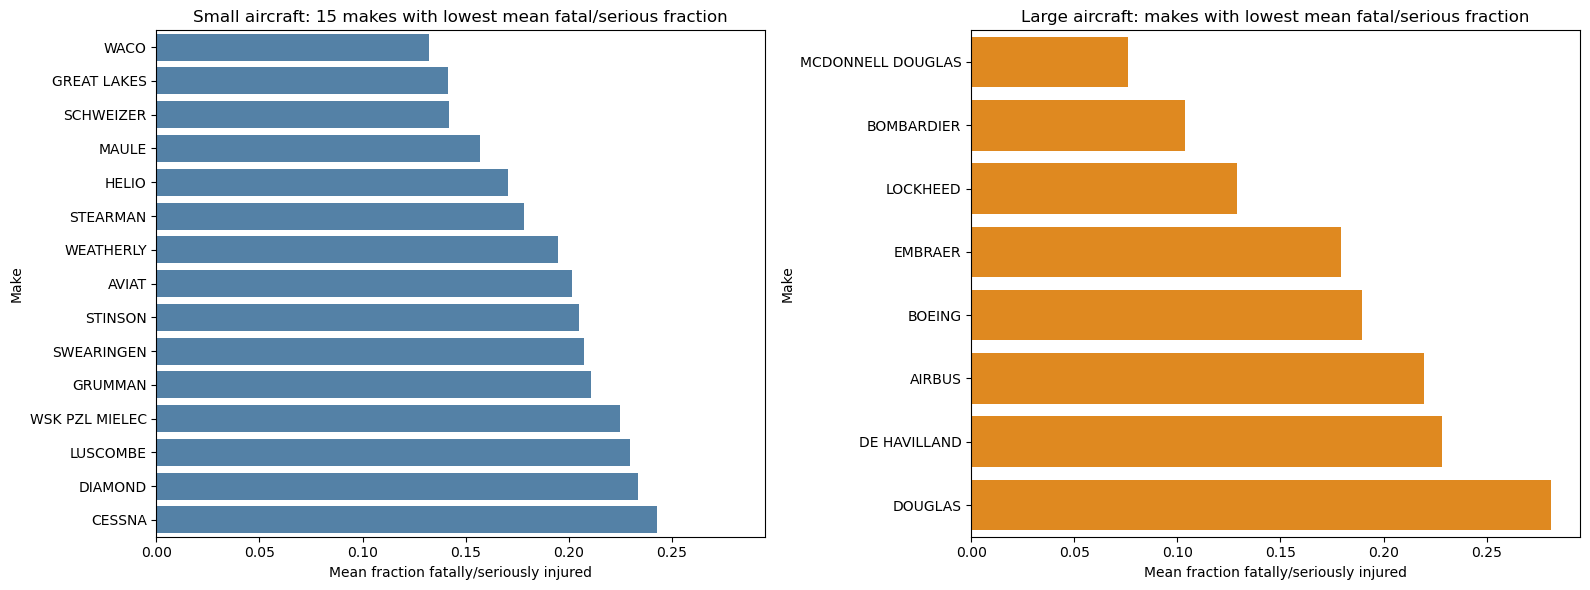

In [8]:
def make_summary(data, min_accidents):
    summary = data.groupby('Make').agg(accidents=('Make', 'size'),
                                       mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                       destroyed_rate=('Destroyed', 'mean'))
    # keep makes with enough accidents for the means to be reliable
    return summary[summary['accidents'] >= min_accidents]

# at least 30 accidents per small make; large jets have far fewer records so 10 is used
small_makes = make_summary(small[small['Make'].isin(small_makes_list)], 30)
large_makes = make_summary(large, 10)

small_top15 = small_makes.nsmallest(15, 'mean_fatal_serious')
large_top15 = large_makes.nsmallest(15, 'mean_fatal_serious')   # only a handful of large makes qualify
display(small_top15.round(3))
display(large_top15.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
sns.barplot(x=small_top15['mean_fatal_serious'], y=small_top15.index, color='steelblue', ax=axes[0])
axes[0].set_title('Small aircraft: 15 makes with lowest mean fatal/serious fraction')
sns.barplot(x=large_top15['mean_fatal_serious'], y=large_top15.index, color='darkorange', ax=axes[1])
axes[1].set_title('Large aircraft: makes with lowest mean fatal/serious fraction')
for ax in axes:
    ax.set_xlabel('Mean fraction fatally/seriously injured')
    ax.set_ylabel('Make')
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

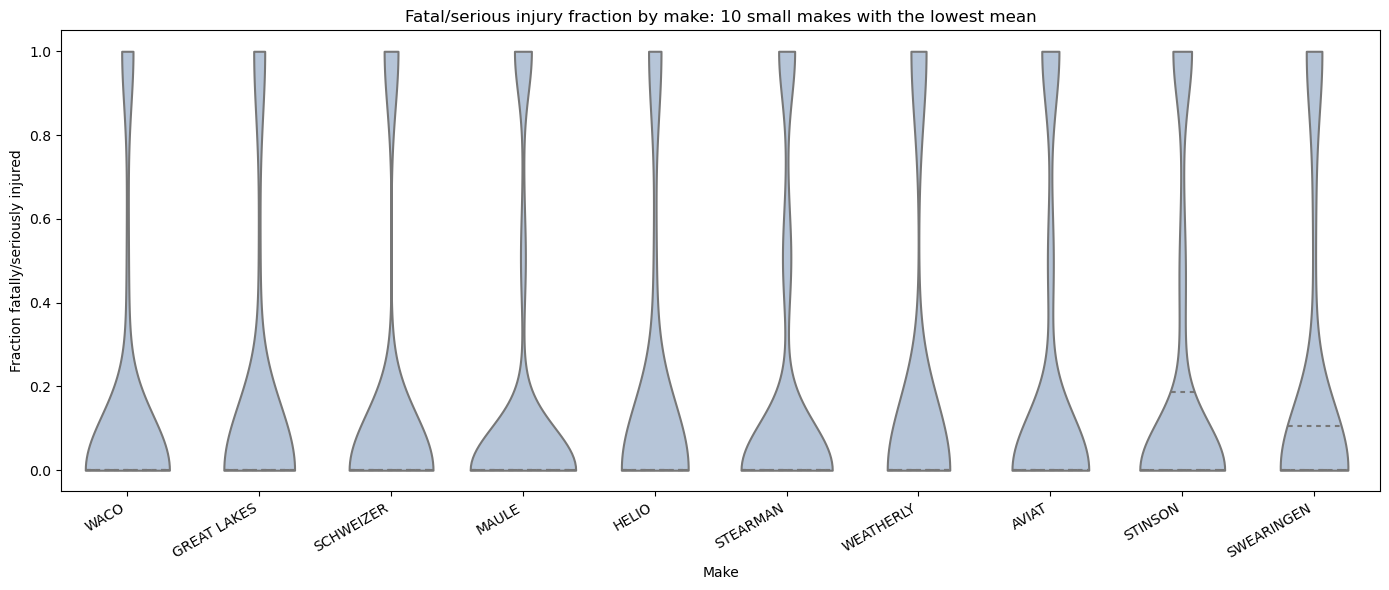

In [9]:
top10_small = small_makes.nsmallest(10, 'mean_fatal_serious').index

plt.figure(figsize=(14, 6))
sns.violinplot(data=small[small['Make'].isin(top10_small)], x='Make', y='Fatal.Serious.Fraction',
               order=top10_small, cut=0, inner='quartile', color='lightsteelblue')
plt.title('Fatal/serious injury fraction by make: 10 small makes with the lowest mean')
plt.ylabel('Fraction fatally/seriously injured')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

c:\Users\pc\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\pc\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


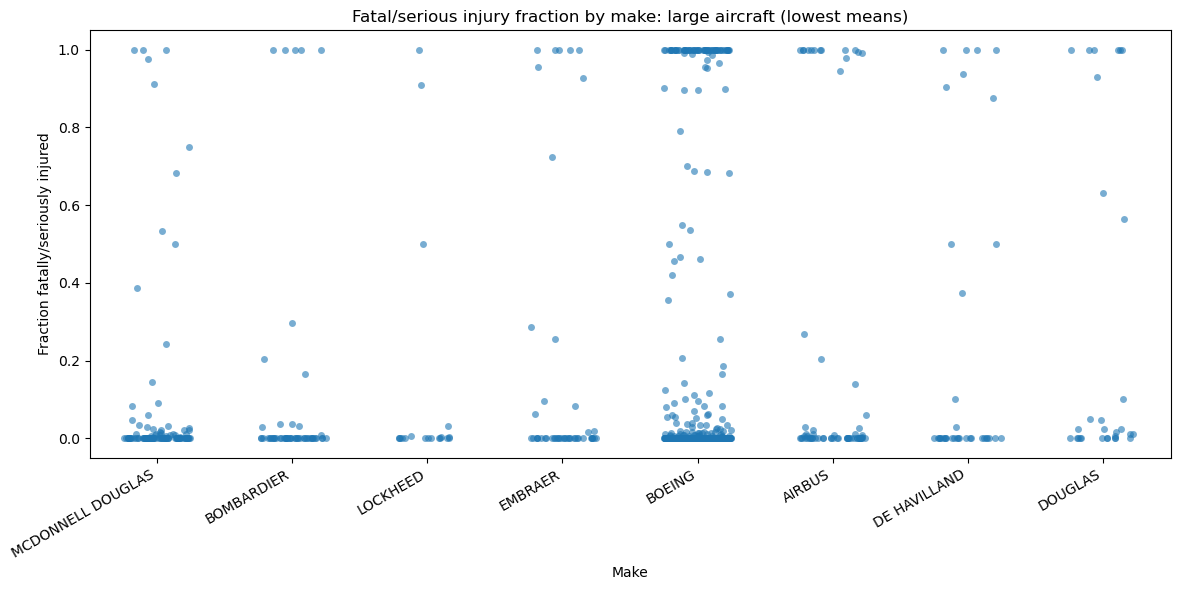

In [10]:
top10_large = large_makes.nsmallest(10, 'mean_fatal_serious').index

plt.figure(figsize=(12, 6))
sns.stripplot(data=large[large['Make'].isin(top10_large)], x='Make', y='Fatal.Serious.Fraction',
              order=top10_large, jitter=0.25, alpha=0.6)
plt.title('Fatal/serious injury fraction by make: large aircraft (lowest means)')
plt.ylabel('Fraction fatally/seriously injured')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

Small aircraft makes with the lowest destroyed rate


,accidents,destroyed_rate
Make,,
AVIAT,221,0.063
DIAMOND,159,0.075
MAULE,488,0.088
STEARMAN,334,0.096
LUSCOMBE,362,0.099
WACO,97,0.103
GREAT LAKES,53,0.113
TAYLORCRAFT,316,0.114
AERONCA,527,0.133


Large aircraft makes with the lowest destroyed rate


,accidents,destroyed_rate
Make,,
BOMBARDIER,56,0.107
MCDONNELL DOUGLAS,115,0.139
EMBRAER,47,0.170
BOEING,422,0.201
LOCKHEED,19,0.211
AIRBUS,67,0.239
DOUGLAS,30,0.267
DE HAVILLAND,36,0.278


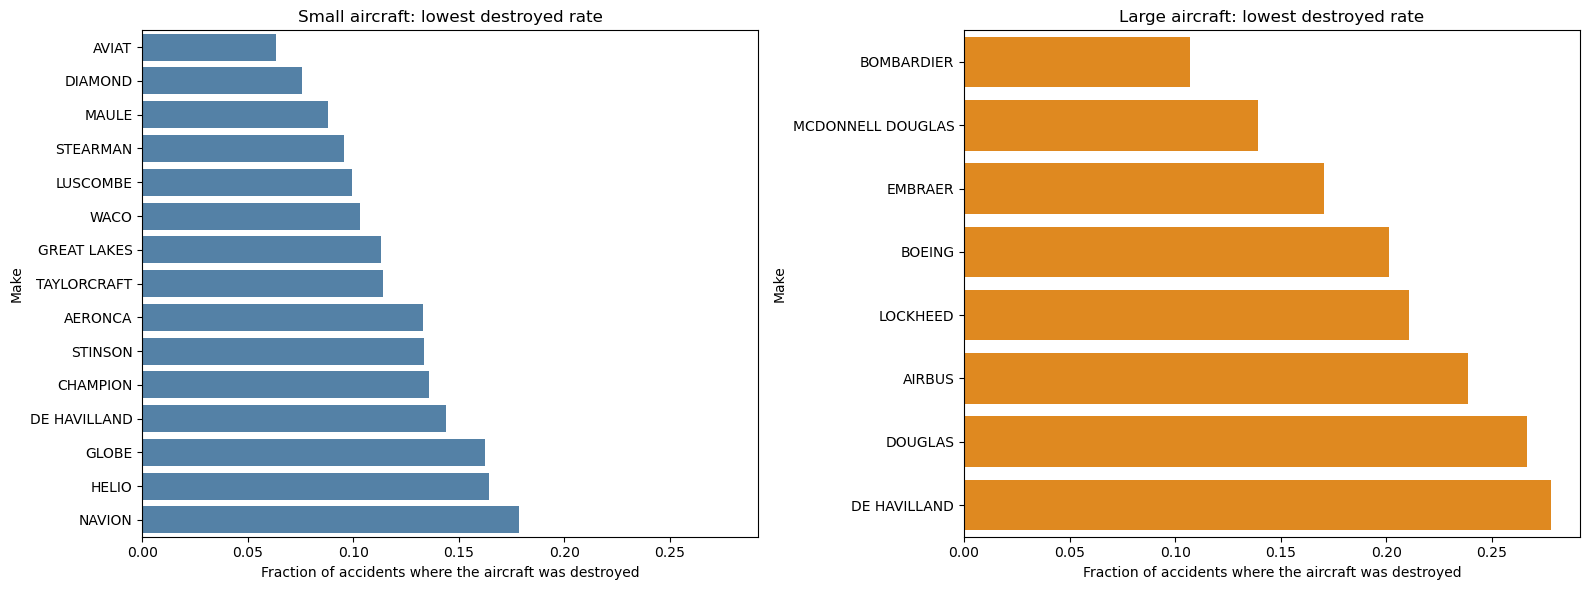

In [11]:
small_destroyed = small_makes.nsmallest(15, 'destroyed_rate')[['accidents', 'destroyed_rate']]
large_destroyed = large_makes.nsmallest(15, 'destroyed_rate')[['accidents', 'destroyed_rate']]
print("Small aircraft makes with the lowest destroyed rate")
display(small_destroyed.round(3))
print("Large aircraft makes with the lowest destroyed rate")
display(large_destroyed.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
sns.barplot(x=small_destroyed['destroyed_rate'], y=small_destroyed.index, color='steelblue', ax=axes[0])
axes[0].set_title('Small aircraft: lowest destroyed rate')
sns.barplot(x=large_destroyed['destroyed_rate'], y=large_destroyed.index, color='darkorange', ax=axes[1])
axes[1].set_title('Large aircraft: lowest destroyed rate')
for ax in axes:
    ax.set_xlabel('Fraction of accidents where the aircraft was destroyed')
    ax.set_ylabel('Make')
plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [12]:
from scipy import stats

def bootstrap_ci(values, n_boot=2000, seed=42):
    """95% bootstrap confidence interval for the mean."""
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, size=len(values)).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5]).round(3)

# Large makes: are the best makes really different from Boeing (the make with the most data)?
boeing = large.loc[large['Make'] == 'BOEING', 'Fatal.Serious.Fraction']
print("BOEING: mean =", round(boeing.mean(), 3), "| 95% CI =", bootstrap_ci(boeing.values))
for make in ['MCDONNELL DOUGLAS', 'BOMBARDIER']:
    a = large.loc[large['Make'] == make, 'Fatal.Serious.Fraction']
    print(f"{make}: mean = {a.mean():.3f} | 95% CI = {bootstrap_ci(a.values)} | "
          f"Mann-Whitney p vs Boeing = {stats.mannwhitneyu(a, boeing).pvalue:.3f}")

# Small makes: Maule (fatal/serious fraction) and Aviat (destroyed rate) against all other small makes
for make, col in [('MAULE', 'Fatal.Serious.Fraction'), ('AVIAT', 'Destroyed')]:
    a = small.loc[small['Make'] == make, col]
    b = small.loc[small['Make'] != make, col]
    print(f"{make} ({col}): {a.mean():.3f} vs {b.mean():.3f} for the other small makes | "
          f"Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.1e}")

# Overall shape of the injury fraction: most accidents are all-or-nothing
print("Share of accidents with fraction 0:", round((df['Fatal.Serious.Fraction'] == 0).mean(), 3),
      "| fraction 1:", round((df['Fatal.Serious.Fraction'] == 1).mean(), 3))

BOEING: mean = 0.19 | 95% CI = [0.154 0.226]
MCDONNELL DOUGLAS: mean = 0.076 | 95% CI = [0.039 0.118] | Mann-Whitney p vs Boeing = 0.138
BOMBARDIER: mean = 0.104 | 95% CI = [0.038 0.193] | Mann-Whitney p vs Boeing = 0.074
MAULE (Fatal.Serious.Fraction): 0.157 vs 0.278 for the other small makes | Mann-Whitney p = 6.4e-10
AVIAT (Destroyed): 0.063 vs 0.211 for the other small makes | Mann-Whitney p = 7.2e-08
Share of accidents with fraction 0: 0.691 | fraction 1: 0.246


**Findings: makes**

*Small aircraft.* The lowest mean fatal/serious fractions belong to Waco (0.13), Great Lakes (0.14), Schweizer (0.14), Maule (0.16), Helio (0.17), Stearman (0.18) and Weatherly (0.20), but Waco and Great Lakes have fewer than 100 accidents each, so their means are less reliable. The best-supported choices are the makes with a few hundred accidents behind them:
- **Maule** (488 accidents): mean fraction 0.157 vs 0.278 for all other small makes (Mann-Whitney p of about 6e-10) and only 8.8% of aircraft destroyed vs 21.2%.
- **Stearman** (334) and **Stinson** (390): fractions of 0.18 and 0.21 with destroyed rates of about 10% and 13%.
- **Aviat** (221) and **Diamond** (159) have the lowest destroyed rates (6.3% and 7.5%, vs 21.1% for other small makes, p of about 1e-7 for Aviat), with moderate fatal/serious fractions of about 0.20 and 0.23.
- **Cessna** and **Piper**, the most common makes by far (24,498 and 13,447 accidents), are in the middle: fractions of 0.24 and 0.30 and destroyed rates of 19% and 23%. Cessna is the best of the high-volume makes and still makes the top 15.

*Large aircraft.* Only eight makes have at least 10 accidents with large aircraft. **McDonnell Douglas** (0.076, 115 accidents) and **Bombardier** (0.104, 56 accidents) are lowest, and these two also have low destroyed rates (13.9% and 10.7%). Boeing, with by far the most data (422 accidents), sits at 0.190 with 20.1% destroyed; Airbus (0.220), De Havilland (0.228) and Douglas (0.281, 30 accidents) are higher. Lockheed looks good (0.129) but has only 19 accidents, so it is not robust.

*Statistical reliability.* The injury fraction is all-or-nothing: 69% of accidents have a fraction of 0 and 25% have a fraction of 1. So the mean is really the share of accidents that were catastrophic, and the distributions in the violin and strip plots are bimodal. For large aircraft, the bootstrap 95% intervals of McDonnell Douglas and Boeing do not overlap, but the Mann-Whitney test is not significant (p of about 0.14), so the large-aircraft ranking is suggestive rather than conclusive. The small-aircraft results for Maule and Aviat are strongly significant. These are rates per accident, not per flight hour, so fleet size and how the aircraft are used are not accounted for.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,accidents,mean_fatal_serious,destroyed_rate
Plane.Type,,,
MCDONNELL DOUGLAS MD-88,12,0.005,0.000
BOMBARDIER CL-600-2B19,21,0.062,0.048
MCDONNELL DOUGLAS MD-11,14,0.093,0.214
BOEING 727-200,11,0.095,0.091
BOEING 737-300,15,0.109,0.200
BOEING 747,14,0.150,0.143
BOEING 767,13,0.176,0.231
BOEING 737,65,0.248,0.200
DE HAVILLAND DHC-6-300,20,0.308,0.350


c:\Users\pc\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\pc\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


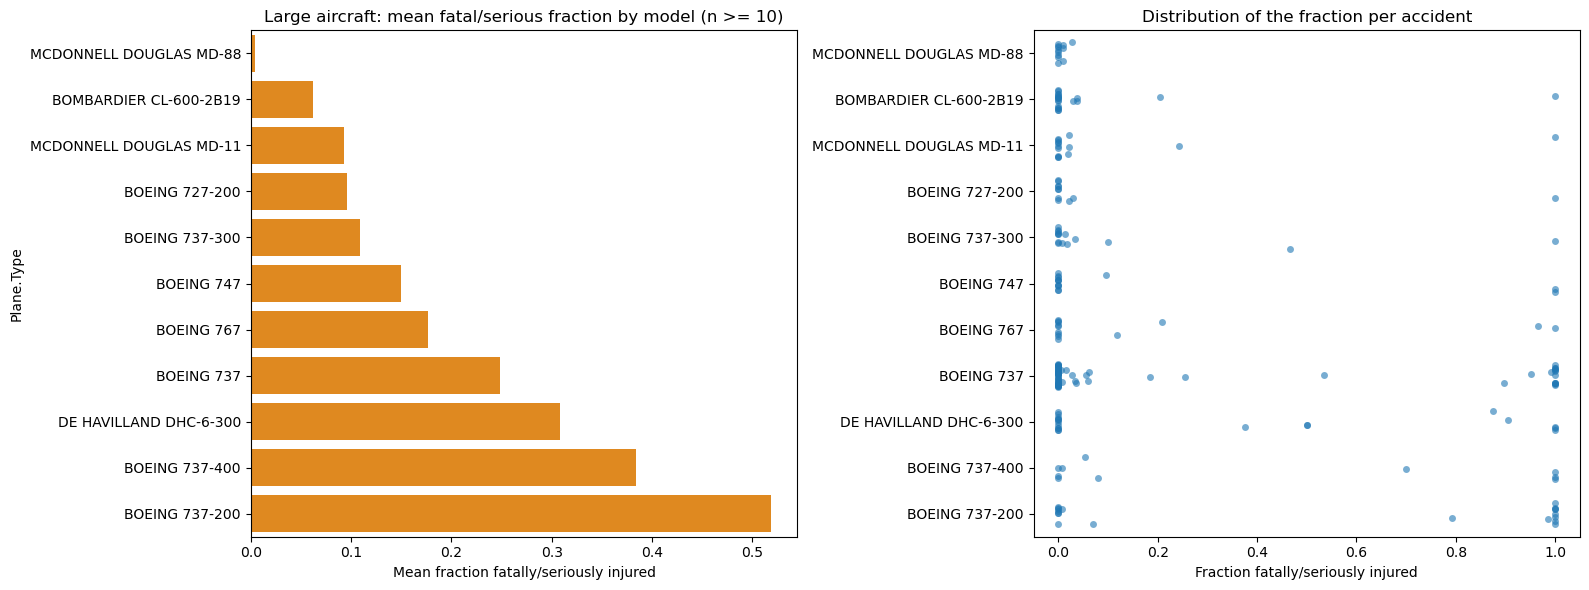

In [13]:
def type_summary(data, min_accidents=10):
    summary = data.groupby('Plane.Type').agg(accidents=('Make', 'size'),
                                             mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                             destroyed_rate=('Destroyed', 'mean'))
    # at least ten accidents per model so each average is based on enough examples
    return summary[summary['accidents'] >= min_accidents].sort_values('mean_fatal_serious')

large_types = type_summary(large)
display(large_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=large_types['mean_fatal_serious'], y=large_types.index, color='darkorange', ax=axes[0])
axes[0].set_title('Large aircraft: mean fatal/serious fraction by model (n >= 10)')
axes[0].set_xlabel('Mean fraction fatally/seriously injured')
sns.stripplot(data=large[large['Plane.Type'].isin(large_types.index)], x='Fatal.Serious.Fraction', y='Plane.Type',
              order=large_types.index, jitter=0.25, alpha=0.6, ax=axes[1])
axes[1].set_title('Distribution of the fraction per accident')
axes[1].set_xlabel('Fraction fatally/seriously injured')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,accidents,mean_fatal_serious,destroyed_rate
Plane.Type,,,
MAULE MX-7-235,17,0.029,0.000
MAULE M-7-235B,10,0.050,0.000
MAULE M-4,18,0.056,0.056
STEARMAN E75,43,0.070,0.093
WEATHERLY 201B,27,0.074,0.111
SWEARINGEN SA226TC,21,0.095,0.095
MAULE M-4-220C,37,0.108,0.081
STINSON 108-1,82,0.114,0.146
GREAT LAKES 2T-1A-2,38,0.118,0.132


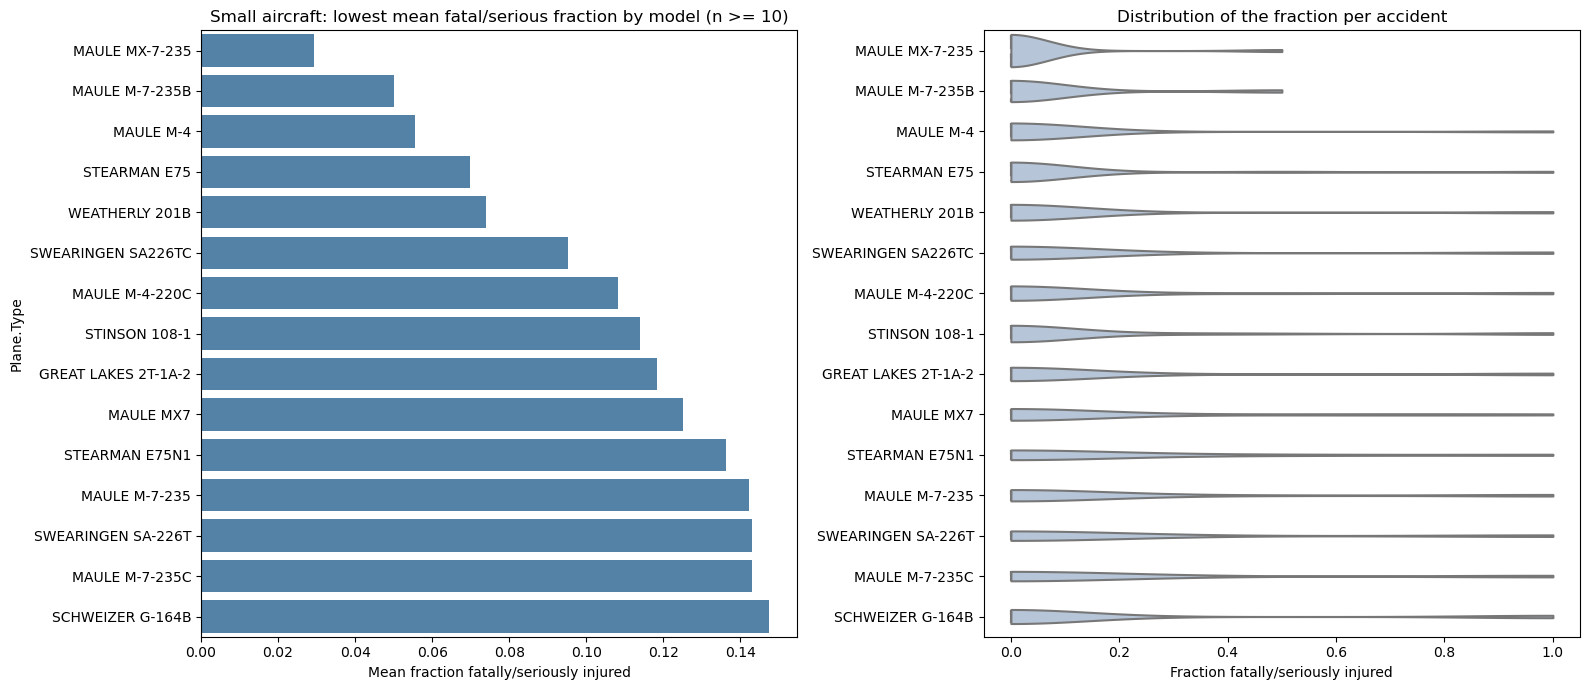

In [14]:
# Models (>= 10 accidents) from the 10 small makes with the lowest mean fatal/serious fraction
small_type_pool = small[small['Make'].isin(top10_small)]
small_types = type_summary(small_type_pool)
small_types_top = small_types.head(15)    # 15 lowest, to keep the plot readable
display(small_types_top.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(x=small_types_top['mean_fatal_serious'], y=small_types_top.index, color='steelblue', ax=axes[0])
axes[0].set_title('Small aircraft: lowest mean fatal/serious fraction by model (n >= 10)')
axes[0].set_xlabel('Mean fraction fatally/seriously injured')
sns.violinplot(data=small_type_pool[small_type_pool['Plane.Type'].isin(small_types_top.index)],
               x='Fatal.Serious.Fraction', y='Plane.Type', order=small_types_top.index,
               cut=0, inner='quartile', color='lightsteelblue', ax=axes[1])
axes[1].set_title('Distribution of the fraction per accident')
axes[1].set_xlabel('Fraction fatally/seriously injured')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Findings: plane types (at least 10 accidents each)**

*Large aircraft.* The lowest fatal/serious fractions are for the **McDonnell Douglas MD-88** (0.005, 12 accidents, none destroyed), **Bombardier CL-600-2B19** (0.062, 21 accidents), **MD-11** (0.093, 14), **Boeing 727-200** (0.095, 11), **737-300** (0.109, 15) and **747** (0.150, 14). The worst are the older **Boeing 737-200** (0.519, 19 accidents, 58% destroyed) and **737-400** (0.384, 10 accidents, 50% destroyed), and the **DHC-6-300** (0.308). The generic Boeing 737 label has the most data (65 accidents, 0.248), which is a good reminder that a make can contain both good and poor models. Sample sizes are only 10 to 21 per model, so these are indicative, not definitive.

*Small aircraft.* Within the 10 best small makes, **Maule** models dominate: the MX-7-235 (0.029, 17 accidents, none destroyed), M-7-235B (0.050, 10), M-4 (0.056, 18) and M-4-220C (0.108, 37) all appear. The best supported by data are **Stearman E75** (0.070, 43 accidents), **Stinson 108-1** (0.114, 82), **Great Lakes 2T-1A-2** (0.118, 38) and **Weatherly 201B** (0.074, 27), an agricultural aircraft. The **Swearingen SA226TC** (0.095, 21) is the one turboprop on the list. Many of these are low-speed utility or vintage types, which partly explains their low severity.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,accidents,mean_fatal_serious,destroyed_rate
Weather.Condition,,,
IMC,4390,0.677,0.590
VMC,48480,0.224,0.166


accidents  mean_fatal_serious  destroyed_rate
Size  Weather.Condition                                               
Large IMC                      125               0.287           0.328
      VMC                      465               0.090           0.097
Small IMC                     4265               0.688           0.598
      VMC                    48015               0.225           0.167

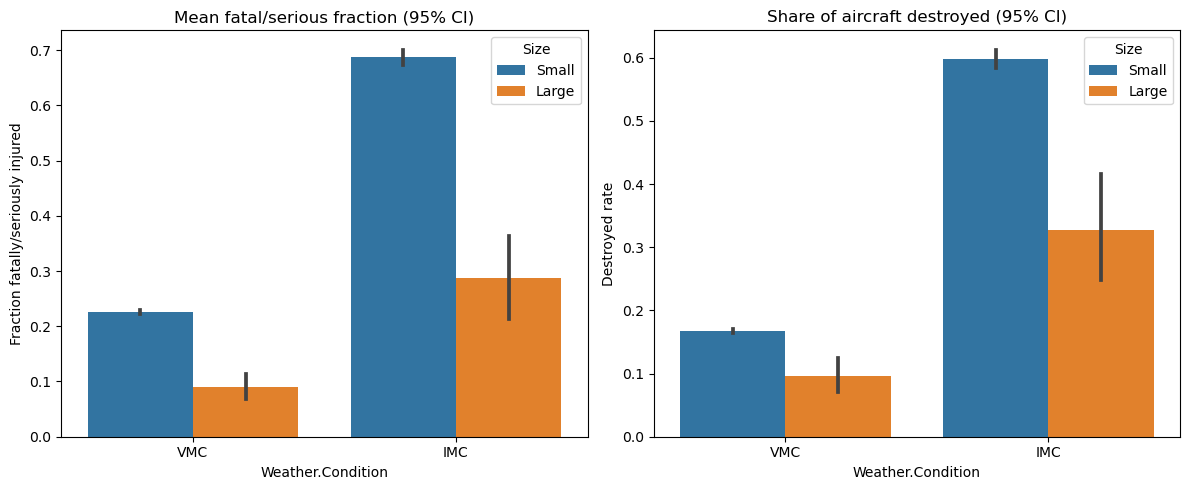

Mann-Whitney U (fatal/serious fraction, IMC vs VMC): p = 0.0
Chi-square (destroyed vs weather): p = 0.0


In [15]:
# Factor 1: Weather condition (VMC = visual conditions, IMC = instrument conditions, i.e. poor visibility)
from scipy import stats

weather = df.dropna(subset=['Weather.Condition'])

weather_table = weather.groupby('Weather.Condition').agg(accidents=('Make', 'size'),
                                                       mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                                       destroyed_rate=('Destroyed', 'mean'))
display(weather_table.round(3))
display(weather.groupby(['Size', 'Weather.Condition']).agg(accidents=('Make', 'size'),
                                                           mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                                           destroyed_rate=('Destroyed', 'mean')).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=weather, x='Weather.Condition', y='Fatal.Serious.Fraction', hue='Size', ax=axes[0])
axes[0].set_title('Mean fatal/serious fraction (95% CI)')
axes[0].set_ylabel('Fraction fatally/seriously injured')
sns.barplot(data=weather, x='Weather.Condition', y='Destroyed', hue='Size', ax=axes[1])
axes[1].set_title('Share of aircraft destroyed (95% CI)')
axes[1].set_ylabel('Destroyed rate')
plt.tight_layout()
plt.show()

# Statistical tests: is the difference between IMC and VMC larger than chance?
imc = weather.loc[weather['Weather.Condition'] == 'IMC', 'Fatal.Serious.Fraction']
vmc = weather.loc[weather['Weather.Condition'] == 'VMC', 'Fatal.Serious.Fraction']
print("Mann-Whitney U (fatal/serious fraction, IMC vs VMC): p =", stats.mannwhitneyu(imc, vmc).pvalue)
chi2, p, dof, expected = stats.chi2_contingency(pd.crosstab(weather['Weather.Condition'], weather['Destroyed']))
print("Chi-square (destroyed vs weather): p =", p)

**Weather condition.** Accidents in instrument conditions (IMC, 4,390 accidents) are far more severe than in visual conditions (VMC, 48,480). The mean fatal/serious fraction is **0.677 vs 0.224** and **59.0% of aircraft are destroyed vs 16.6%**. The pattern holds in both size groups: for large aircraft 0.287 vs 0.090 and 32.8% vs 9.7% destroyed, and for small aircraft 0.688 vs 0.225 and 59.8% vs 16.7%. Both tests give p of about 0, and the confidence intervals in the plot do not overlap. IMC accidents are therefore about three times as likely to be fatal or serious and about 3.5 times as likely to destroy the aircraft, so weather (and instrument-flight risk) matters more for the insurer than the choice of make.

,accidents,mean_fatal_serious,destroyed_rate
Broad.phase.of.flight,,,
Maneuvering,4252,0.525,0.468
Climb,1249,0.442,0.443
Other,52,0.430,0.365
Cruise,6504,0.356,0.345
Approach,4167,0.355,0.303
Descent,1145,0.354,0.341
Go-around,1092,0.301,0.288
Takeoff,8077,0.228,0.219
Standing,439,0.091,0.125


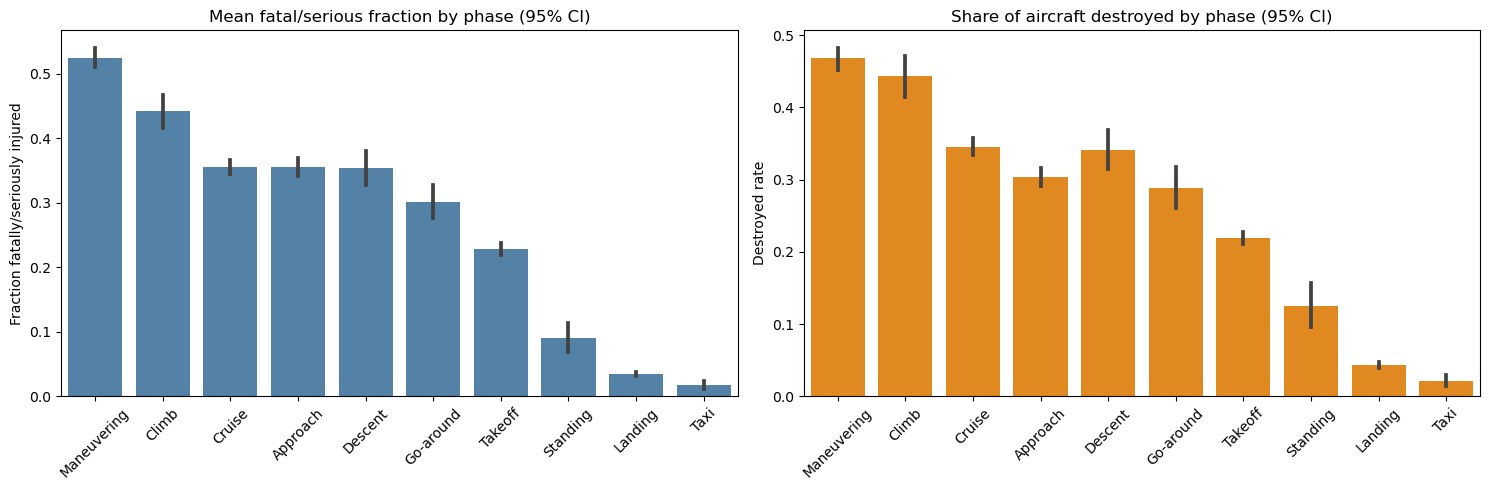

Chi-square (destroyed vs phase of flight): p = 0.0
Kruskal-Wallis (fatal/serious fraction across phases): p = 0.0


In [16]:
# Factor 2: Broad phase of flight
phase = df.dropna(subset=['Broad.phase.of.flight'])

phase_table = phase.groupby('Broad.phase.of.flight').agg(accidents=('Make', 'size'),
                                                       mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                                       destroyed_rate=('Destroyed', 'mean'))
phase_table = phase_table.sort_values('mean_fatal_serious', ascending=False)
display(phase_table.round(3))

# only phases with a robust number of accidents are plotted
phase_order = phase_table[phase_table['accidents'] >= 100].index

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=phase[phase['Broad.phase.of.flight'].isin(phase_order)], x='Broad.phase.of.flight',
            y='Fatal.Serious.Fraction', order=phase_order, color='steelblue', ax=axes[0])
axes[0].set_title('Mean fatal/serious fraction by phase (95% CI)')
axes[0].set_ylabel('Fraction fatally/seriously injured')
sns.barplot(data=phase[phase['Broad.phase.of.flight'].isin(phase_order)], x='Broad.phase.of.flight',
            y='Destroyed', order=phase_order, color='darkorange', ax=axes[1])
axes[1].set_title('Share of aircraft destroyed by phase (95% CI)')
axes[1].set_ylabel('Destroyed rate')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

chi2, p, dof, expected = stats.chi2_contingency(pd.crosstab(phase['Broad.phase.of.flight'], phase['Destroyed']))
print("Chi-square (destroyed vs phase of flight): p =", p)
print("Kruskal-Wallis (fatal/serious fraction across phases): p =",
      stats.kruskal(*[g['Fatal.Serious.Fraction'] for _, g in phase.groupby('Broad.phase.of.flight')]).pvalue)

**Phase of flight.** Severity depends strongly on the phase in which the accident happens (tests p of about 0). **Maneuvering** is the worst (fraction 0.525, 46.8% destroyed, 4,252 accidents), followed by **climb** (0.442, 44.3%), cruise (0.356, 34.5%), approach (0.355, 30.3%) and descent (0.354, 34.1%). **Landing** is the most common phase (10,983 accidents) but one of the safest: fraction 0.035 and only 4.3% destroyed. Taxi (0.017, 2.1%) and standing (0.091, 12.5%) are similar. The phases at altitude or high speed are the deadly ones, while slow ground-level phases mostly give minor damage. Phases like Other (52 accidents) are too small to trust, which is why only phases with at least 100 accidents are plotted.

,accidents,mean_fatal_serious,destroyed_rate
Number.of.Engines,,,
1.0,45885,0.251,0.185
2.0,6811,0.352,0.314
3.0,124,0.089,0.129
4.0,137,0.299,0.292


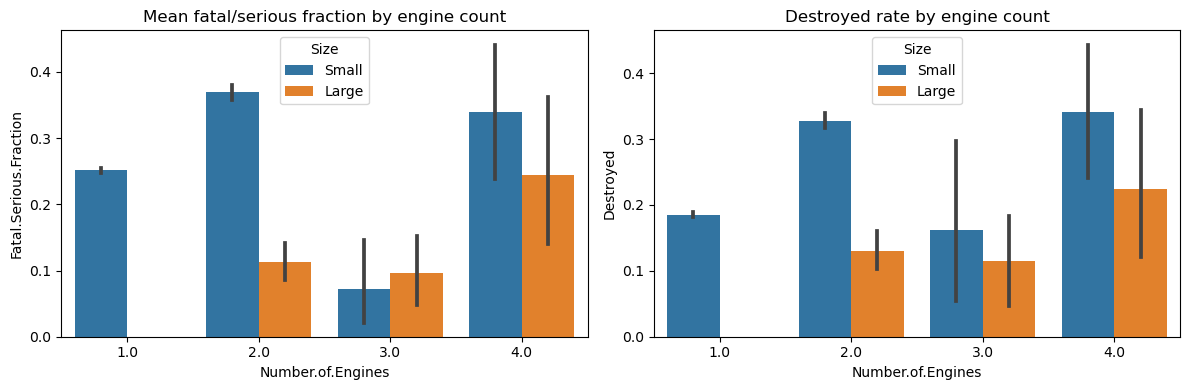

In [17]:
# Bonus factor: Number of engines
engines = df.dropna(subset=['Number.of.Engines'])
engine_table = engines.groupby('Number.of.Engines').agg(accidents=('Make', 'size'),
                                                       mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                                       destroyed_rate=('Destroyed', 'mean'))
display(engine_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=engines, x='Number.of.Engines', y='Fatal.Serious.Fraction', hue='Size', ax=axes[0])
axes[0].set_title('Mean fatal/serious fraction by engine count')
sns.barplot(data=engines, x='Number.of.Engines', y='Destroyed', hue='Size', ax=axes[1])
axes[1].set_title('Destroyed rate by engine count')
plt.tight_layout()
plt.show()

**Number of engines (extra factor).** Single-engine aircraft have a mean fraction of 0.251 and 18.5% destroyed (45,885 accidents), while twin-engine aircraft have 0.352 and 31.4% destroyed (6,811 accidents). Twins are heavier, faster and more often flown in demanding conditions, so this is not evidence that an extra engine is dangerous by itself. The three- and four-engine groups have only 124 and 137 accidents, so their means (0.089 and 0.299) are not reliable.

## Recommendations

**Small aircraft makes:** Maule, Stearman, Stinson, Aviat and Diamond combine low fatal/serious fractions or low destroyed rates with a few hundred accidents of evidence. Cessna is the best high-volume option. Specific models: Maule M-4-220C and M-7-235, Stearman E75, Stinson 108-1, Great Lakes 2T-1A-2 and Weatherly 201B.

**Large aircraft makes:** McDonnell Douglas and Bombardier have the lowest rates, with Boeing as a reliable large-sample benchmark (0.190). Specific models: McDonnell Douglas MD-88 and MD-11, Bombardier CL-600-2B19, and Boeing 727-200, 737-300 and 747. Older Boeing 737-200 and 737-400 models should be treated as higher risk. Because large-aircraft samples are small, these rankings are suggestive.

**Other factors:** accidents in instrument weather (IMC) and during maneuvering, climb or cruise are the most severe, whereas landing and taxi accidents are mostly survivable. The insurer should weigh operating conditions as well as make and model.

**Limitations:** the data contain accidents only (no flight hours or fleet size), so these are severity rates after an accident, not accident likelihoods.